### Dylan Renard
### Applied Machine Learning JHU
### Homework 10
### Professor Alhassan
### April 4th, 2026

## HW Assignment 10: Applied Machine Learning @JHU
In this assignment,  we will develop a ML model for cybersecurity intrusion  detection.  
Please visit the website:  https://www.unb.ca/cic/datasets/ids-2017.html andlook around  to see the problem space and the evaluation  datasets  to be used  for ML model development. 

This  dataset  was collected by cyber experts during  experimentation  that was carried  out over the course of 5 days. 
The description of the experiments  also  informs the experimental  ground 
truth.
 
(Suggested:  GeneratedLabelledFlows.zip; note that it is already pre-processed  by someone) 


#### Q1: Download  the labeled  dataset  (if you like, use a dummy email address  for registration).  There must be 8 data files, each representing  a particular  cyber-attack type, its day, and its collected packet capture (“PCAP”) data. 

In [3]:
import pandas as pd

df = pd.read_csv("TrafficLabelling /Monday-WorkingHours.pcap_ISCX.csv")

print(df.shape)
print(df.columns)
print(df[' Label'].value_counts())

(529918, 85)
Index(['Flow ID', ' Source IP', ' Source Port', ' Destination IP',
       ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration',
       ' Total Fwd Packets', ' Total Backward Packets',
       'Total Length of Fwd Packets', ' Total Length of Bwd Packets',
       ' Fwd Packet Length Max', ' Fwd Packet Length Min',
       ' Fwd Packet Length Mean', ' Fwd Packet Length Std',
       'Bwd Packet Length Max', ' Bwd Packet Length Min',
       ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s',
       ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max',
       ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std',
       ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean',
       ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags',
       ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags',
       ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s',
       ' Bwd Packets/s', ' Min Packet Leng

#### Q2: Pick one of the data files, call it Dataset  1, and examine its features. Make sure it has more than one class  value for its label

In [4]:
import os

data_dir = 'TrafficLabelling '
files = [f for f in os.listdir(data_dir) if f.endswith(".csv")]

results = []

for file in files:
    file_path = os.path.join(data_dir, file)
    
    try:
        try:
            df = pd.read_csv(file_path, encoding='utf-8')
        except UnicodeDecodeError:
            df = pd.read_csv(file_path, encoding='latin1')
        
        df.columns = df.columns.str.strip()
        
        label_counts = df['Label'].value_counts()
        num_classes = df['Label'].nunique()
        
        results.append({
            "Dataset": file,
            "Num Classes": num_classes,
            "Has Multiple Classes": num_classes > 1,
            "Class Breakdown": dict(label_counts)
        })
        
    except Exception as e:
        results.append({
            "Dataset": file,
            "Num Classes": -1,
            "Has Multiple Classes": False,
            "Class Breakdown": str(e)
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Num Classes", ascending=False).reset_index(drop=True)

pd.set_option('display.max_colwidth', None)
results_df

/var/folders/_s/w6hdbcxj4_5dmvd3cyhy3p580000gn/T/ipykernel_3239/315412566.py:15: DtypeWarning: Columns (0,1,3,6,84) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, encoding='latin1')


,Dataset,Num Classes,Has Multiple Classes,Class Breakdown
0,Wednesday-workingHours.pcap_ISCX.csv,6,True,"{'BENIGN': 440031, 'DoS Hulk': 231073, 'DoS GoldenEye': 10293, 'DoS slowloris': 5796, 'DoS Slowhttptest': 5499, 'Heartbleed': 11}"
1,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,4,True,"{'BENIGN': 168186, 'Web Attack  Brute Force': 1507, 'Web Attack  XSS': 652, 'Web Attack  Sql Injection': 21}"
2,Tuesday-WorkingHours.pcap_ISCX.csv,3,True,"{'BENIGN': 432074, 'FTP-Patator': 7938, 'SSH-Patator': 5897}"
3,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,2,True,"{'BENIGN': 288566, 'Infiltration': 36}"
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,2,True,"{'BENIGN': 189067, 'Bot': 1966}"
5,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,2,True,"{'PortScan': 158930, 'BENIGN': 127537}"
6,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,2,True,"{'DDoS': 128027, 'BENIGN': 97718}"
7,Monday-WorkingHours.pcap_ISCX.csv,1,False,{'BENIGN': 529918}


#### Q2 Interpretation:
The Wednesday-workingHours.pcap_ISCX.csv dataset was selected as Dataset 1 because it provides both the largest sample size and the greatest class diversity among the available datasets. It contains six distinct labels: BENIGN (440,031), DoS Hulk (231,073), DoS GoldenEye (10,293), DoS slowloris (5,796), DoS Slowhttptest (5,499), and Heartbleed (11). This results in a total of over 690,000 observations, offering a robust sample size for model training. 

Although the dataset is highly imbalanced at the individual class level, aggregating all attack types yields approximately 252,672 attack samples compared to 440,031 benign samples, producing a more moderate imbalance in a binary setting. This binary distribution (~36% attack vs ~64% benign) is still moderately imbalanced and may influence classifier bias, which will be considered in later modeling steps.

The combination of large sample size and diverse attack representation motivated the selection of this dataset over others, such as the Monday dataset, which contains only benign traffic.

#### Q3: For your Dataset  1, pick a machine learning  methodology  and  justify your choice. 

As discussed in the module textbook, particularly in Chapter 7 on ensemble learning, Random Forest is well suited for high dimensional tabular data and for capturing nonlinear relationships between features. Based on these characteristics, a Random Forest classifier was selected for this dataset. The Wednesday-workingHours dataset contains a wide range of flow level features, including packet counts, byte rates, inter arrival times, and TCP flag statistics, which are likely to interact in complex, non linear ways when distinguishing between benign and malicious traffic.

Random Forest works well in this setting because it does not require feature scaling, can handle different types of feature distributions, and reduces overfitting by averaging across multiple decision trees. By training trees on different subsets of the data and features, the model is able to learn more generalizable patterns and avoid relying too heavily on any single feature (Raschka et al., 2022, Chapter 7).

The dataset contains hundreds of engineered flow-based features derived from network traffic, further supporting the need for a model capable of handling high-dimensional feature spaces. Additionally, Random Forest provides feature importance measures, allowing identification of the most influential network traffic characteristics, which is valuable in intrusion detection settings where interpretability and insight into feature relevance are important.

Compared to Logistic Regression, Random Forest does not assume linear separability, making it more suitable for capturing complex interactions in network traffic data. While Gradient Boosting could also model nonlinear relationships, Random Forest provides a more robust and less sensitive baseline with reduced risk of overfitting and simpler tuning. Additionally, Random Forest can better handle potential class imbalance in intrusion detection tasks through techniques such as class weighting or balanced subsampling.

Overall, Random Forest provides a good balance between performance, robustness, and interpretability for this type of classification problem.


#### Q4: Process  the class feature/category  as binary classes  for supervised  learning, assign  BENIGN to value 0 and  the rest to value  1. Check its balance  for the  Dataset  1. 

In [5]:
file_path = "TrafficLabelling /Wednesday-workingHours.pcap_ISCX.csv"

# Handle encoding safely
try:
    df = pd.read_csv(file_path, encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding='latin1')

# Clean column names
df.columns = df.columns.str.strip()
df['Label_binary'] = df['Label'].apply(lambda x: 0 if x == 'BENIGN' else 1)

df.groupby(['Label', 'Label_binary']).size()

Label             Label_binary
BENIGN            0               440031
DoS GoldenEye     1                10293
DoS Hulk          1               231073
DoS Slowhttptest  1                 5499
DoS slowloris     1                 5796
Heartbleed        1                   11
dtype: int64

##### Q4 Interpretation:
After converting the labels to a binary classification problem, the dataset contains 440,031 benign samples (class 0) and 252,672 attack samples (class 1), corresponding to approximately 63.5% benign traffic and 36.5% attack traffic. This indicates a moderate class imbalance, with benign traffic representing the majority class.

Although this imbalance is less severe than the original multiclass distribution, it may still affect supervised learning by biasing some classifiers toward the majority class. In the context of intrusion detection, this is important because misclassifying attack traffic as benign would reduce the usefulness of the model in practice. Accordingly, evaluation will emphasize metrics such as recall and F1-score for the attack class in addition to overall accuracy.

#### Q5: Explore Dataset  1 features  with respect  to the class. (Hint: features  Source Port and Destination Port are very useful; research  and find out important  networking  port numbers  and one-hot-encode  them. Unimportant  port numbers or source port numbers can be assigned  to a feature called 'other ports'.) 

/Users/drenard921/opt/anaconda3/envs/clean_env_2025/lib/python3.13/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


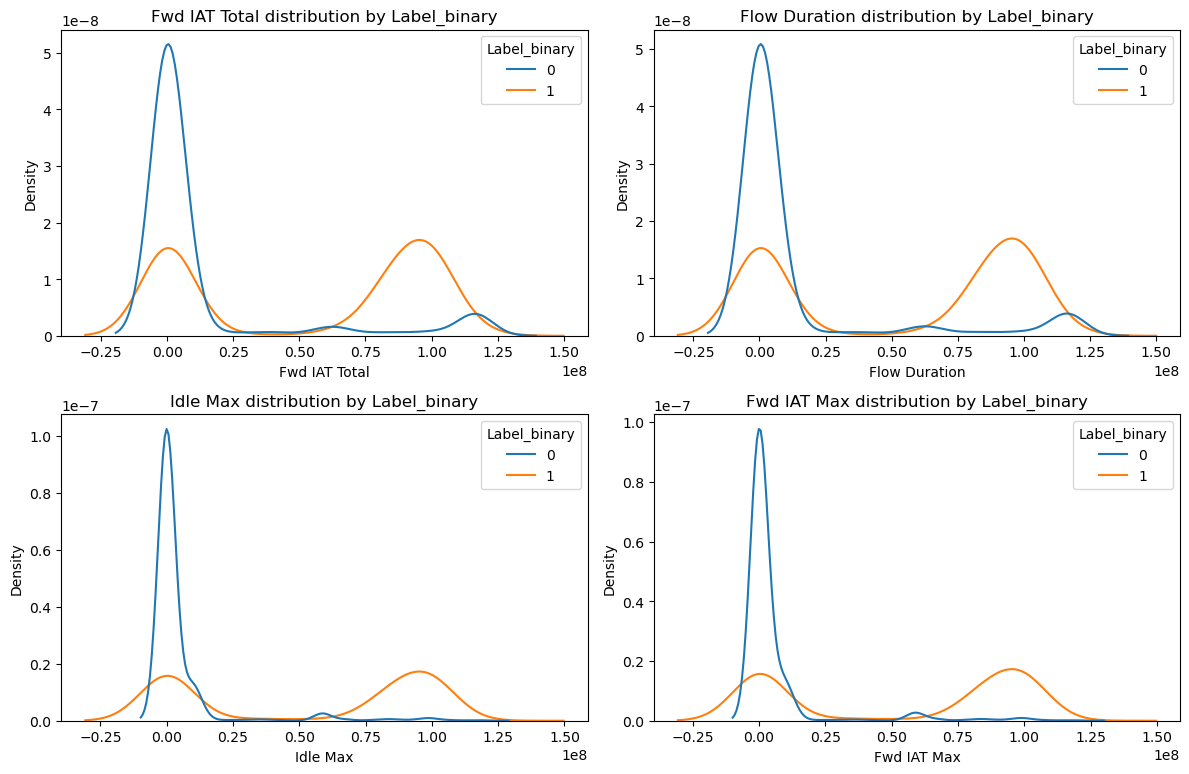

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Sample for speed
df_sample = df.sample(n=5000, random_state=42)

# 2. Select numeric features
numeric_cols = df_sample.select_dtypes(include=['float64', 'int64']).columns
numeric_cols = [col for col in numeric_cols if col not in ['Label_binary']]

# 3. Pick top features by variance (most informative spread)
top_features = df_sample[numeric_cols].var().sort_values(ascending=False).head(4).index

# 4. Plot KDE distributions
plt.figure(figsize=(12, 8))

for i, col in enumerate(top_features, 1):
    plt.subplot(2, 2, i)
    sns.kdeplot(
        data=df_sample,
        x=col,
        hue='Label_binary',
        common_norm=False
    )
    plt.title(f"{col} distribution by Label_binary")

plt.tight_layout()
plt.show()

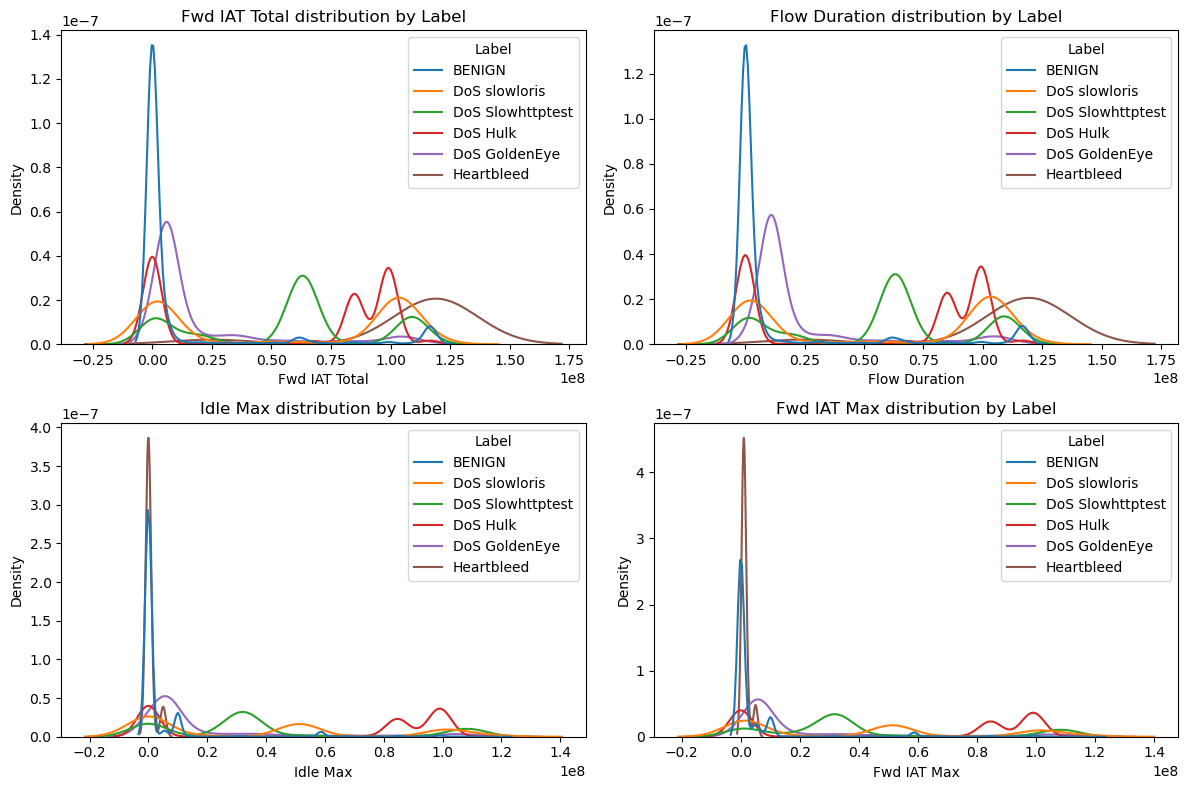

In [7]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(top_features, 1):
    plt.subplot(2, 2, i)
    sns.kdeplot(
        data=df,
        x=col,
        hue='Label',
        common_norm=False
    )
    plt.title(f"{col} distribution by Label")

plt.tight_layout()
plt.show()

/Users/drenard921/opt/anaconda3/envs/clean_env_2025/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [33 34 35 51 58 59 60 61 62 63] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Users/drenard921/opt/anaconda3/envs/clean_env_2025/lib/python3.13/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


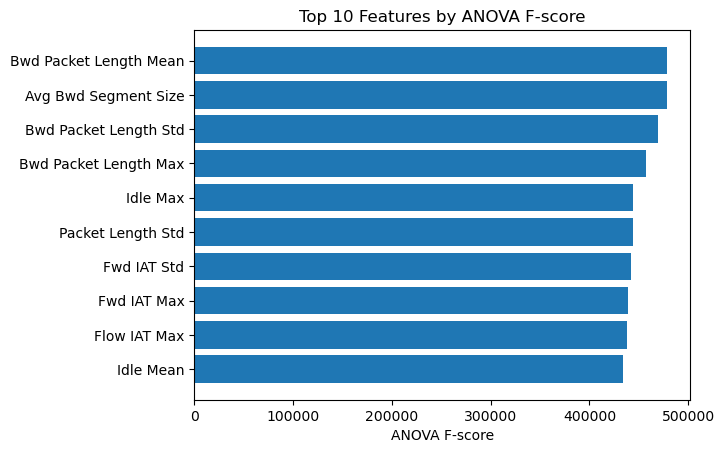

In [8]:
from sklearn.feature_selection import f_classif
import numpy as np
X = df[numeric_cols]
y = df['Label_binary']



# Replace inf with NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Drop columns that are entirely NaN (rare but safe)
X = X.dropna(axis=1, how='all')

# Fill remaining NaNs with median (fast + acceptable here)
X = X.fillna(X.median())

# Compute ANOVA F-scores
f_vals, p_vals = f_classif(X, y)

anova_df = pd.DataFrame({
    'feature': X.columns,
    'F_score': f_vals,
    'p_value': p_vals
}).sort_values(by='F_score', ascending=False)

# Select top 10
top10 = anova_df.head(10)

# Plot (no color specified per rules)
plt.figure()
plt.barh(top10['feature'], top10['F_score'])
plt.xlabel("ANOVA F-score")
plt.title("Top 10 Features by ANOVA F-score")
plt.gca().invert_yaxis()
plt.show()

Label_binary            0         1
DstPortCategory                    
DNS              1.000000  0.000000
FTP              1.000000  0.000000
HTTP             0.161770  0.838230
HTTPS            1.000000  0.000000
OTHER            0.999881  0.000119
SSH              1.000000  0.000000


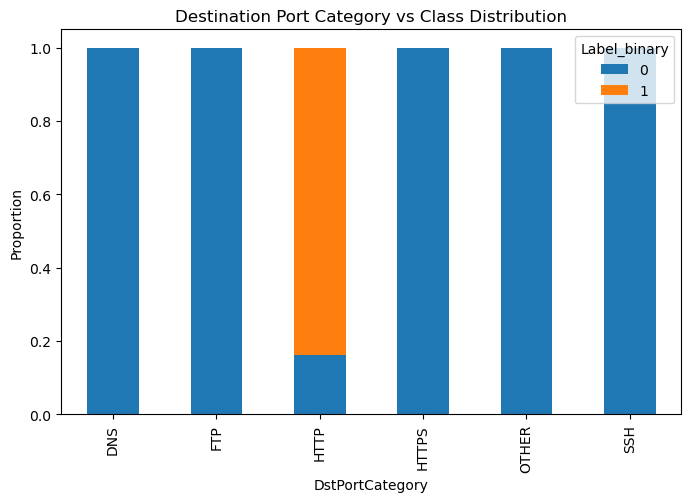

In [20]:
df.columns = df.columns.str.strip()

important_ports = {
    80: "HTTP",
    443: "HTTPS",
    53: "DNS",
    22: "SSH",
    21: "FTP"
}

def categorize_port(port):
    try:
        port = int(port)
    except:
        return "OTHER"
    return important_ports.get(port, "OTHER")

df['SrcPortCategory'] = df['Source Port'].apply(categorize_port)
df['DstPortCategory'] = df['Destination Port'].apply(categorize_port)

src_dummies = pd.get_dummies(df['SrcPortCategory'], prefix='src')
dst_dummies = pd.get_dummies(df['DstPortCategory'], prefix='dst')

df = pd.concat([df, src_dummies, dst_dummies], axis=1)

# 🔑 THIS WAS MISSING
port_vs_class = pd.crosstab(
    df['DstPortCategory'],
    df['Label_binary'],
    normalize='index'
)

print(port_vs_class)

port_vs_class.plot(kind='bar', stacked=True, figsize=(8,5))
plt.title("Destination Port Category vs Class Distribution")
plt.ylabel("Proportion")
plt.show()

##### Q5 Exploration results:
The exploratory analysis indicates that both temporal and packet-level features contribute meaningfully to distinguishing between benign and malicious network traffic. Kernel density estimates generated using binary class labels show that benign traffic tends to be concentrated within lower-value ranges, whereas malicious traffic exhibits a broader and more variable distribution. This behavior is consistent with attack patterns such as scanning, flooding, or maintaining persistent connections, which inherently generate longer durations and more irregular timing compared to typical user-driven traffic. This pattern is particularly evident in time-based features such as flow duration and inter-arrival times, suggesting that attack traffic is often associated with longer-lasting and less regular communication behavior.

When extending the analysis to multiclass labels, distinct distributional patterns emerge across different attack types. Certain classes demonstrate clear separation from benign traffic, indicating strong discriminative signals, while others, such as DoS slowloris and DoS GoldenEye, display substantial overlap. This overlap suggests that these attack types share statistical similarities with benign traffic, leading to more complex and less well-defined decision boundaries for classification models.

To quantitatively assess feature importance, an ANOVA F-test was performed to evaluate whether the mean values of each feature differ significantly across traffic classes. This approach is appropriate in this context because it provides a statistical measure of how well each feature separates multiple groups, rather than relying solely on visual inspection. Features with higher F-scores indicate greater between-class variance relative to within-class variance, making them more effective for distinguishing between benign and malicious behavior.

The ANOVA results reinforce the patterns observed in the exploratory analysis by identifying both packet size-related features (e.g., backward packet length statistics) and temporal features (e.g., idle time and inter-arrival time metrics) as having high discriminative power. Collectively, these findings highlight that effective traffic classification depends on capturing both the structural characteristics of packet transmission and the temporal dynamics of network behavior. This suggests that models incorporating both feature types are likely to achieve more robust performance across diverse attack scenarios. This confirms that the observed separation in KDE plots is not incidental but reflects statistically significant differences in feature distributions across classes.

In addition to temporal and packet-level features, network port information was explored by grouping commonly used ports such as HTTP (80), HTTPS (443), DNS (53), SSH (22), and FTP (21), with all other ports categorized as “OTHER.” Analysis of destination port distributions revealed that HTTP traffic contains a substantial proportion of attack samples, while other port categories are almost exclusively associated with benign traffic. This pattern reflects the presence of HTTP-based denial-of-service attacks in the dataset, such as DoS Hulk and Slowloris. These findings indicate that port-based features, particularly those associated with web traffic, provide strong discriminative signals, although they may capture dataset-specific patterns that do not generalize across all network environments.

#### Q6: Display  some histograms  and anything  you deem fit to pick independent  Dataset  1 features.  (Hint: source/destination  bytes,  packets, ports and the duration  features.) 

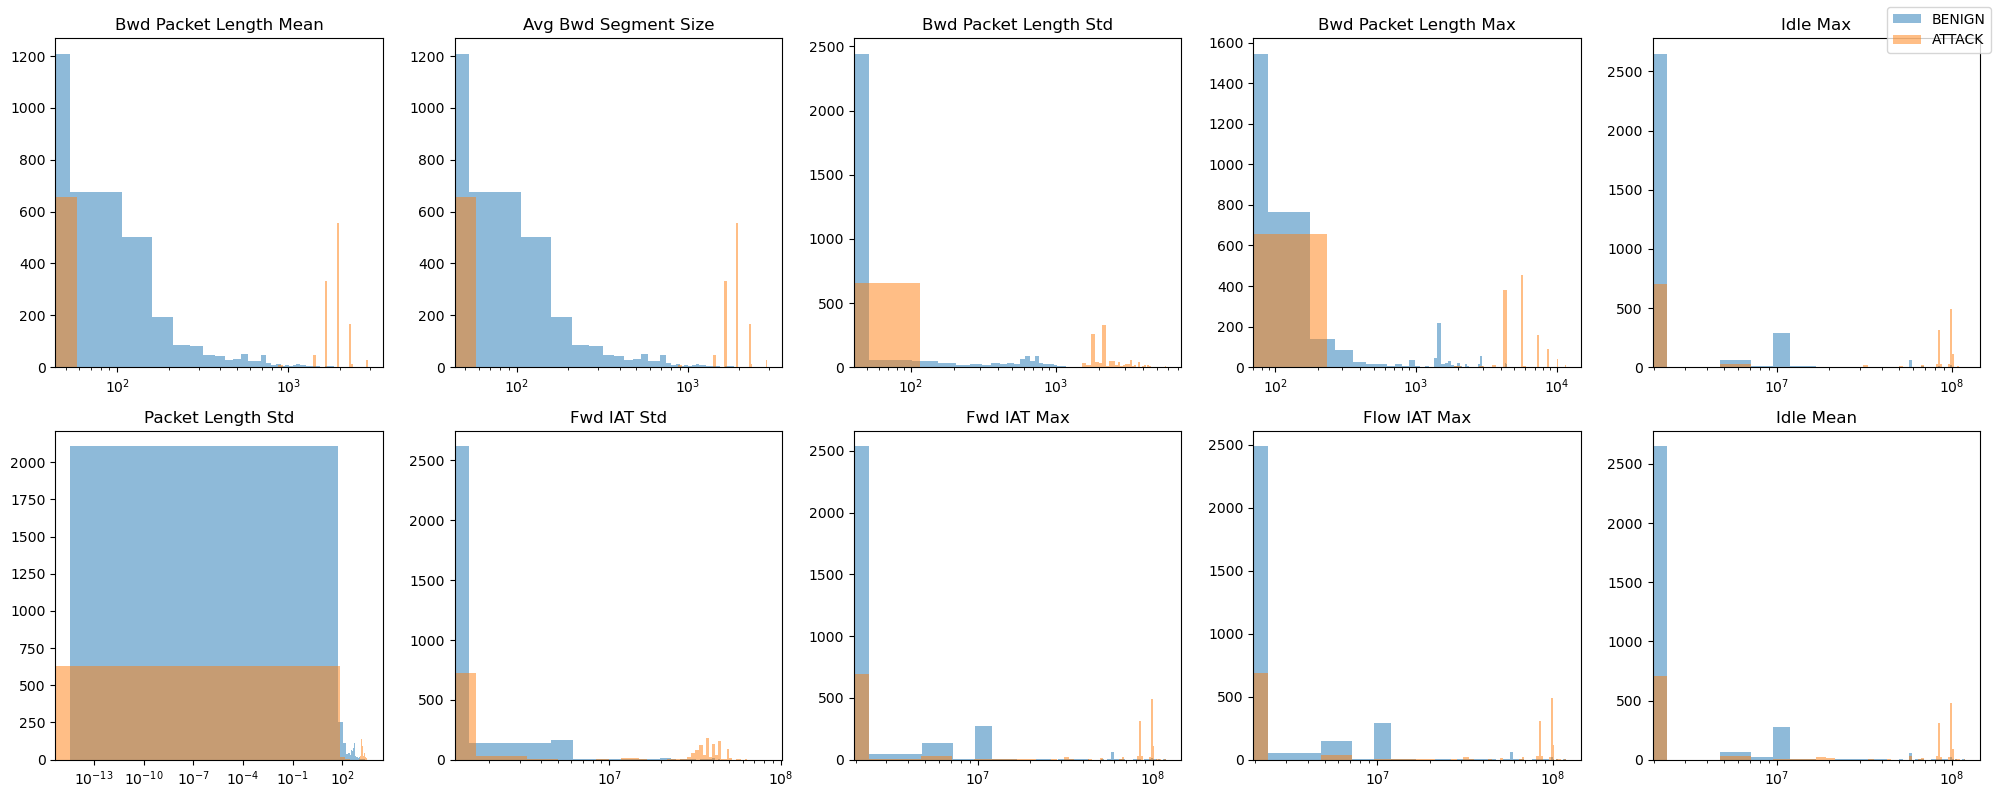

In [21]:

top_features = [
    'Bwd Packet Length Mean',
    'Avg Bwd Segment Size',
    'Bwd Packet Length Std',
    'Bwd Packet Length Max',
    'Idle Max',
    'Packet Length Std',
    'Fwd IAT Std',
    'Fwd IAT Max',
    'Flow IAT Max',
    'Idle Mean'
]

df_sample = df.sample(n=5000, random_state=42)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    ax = axes[i]
    ax.set_xscale('log')
    ax.hist(
        df_sample[df_sample['Label_binary'] == 0][feature],
        bins=50, alpha=0.5, label='BENIGN'
    )
    
    ax.hist(
        df_sample[df_sample['Label_binary'] == 1][feature],
        bins=50, alpha=0.5, label='ATTACK'
    )
    
    ax.set_title(feature)

# Single legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()

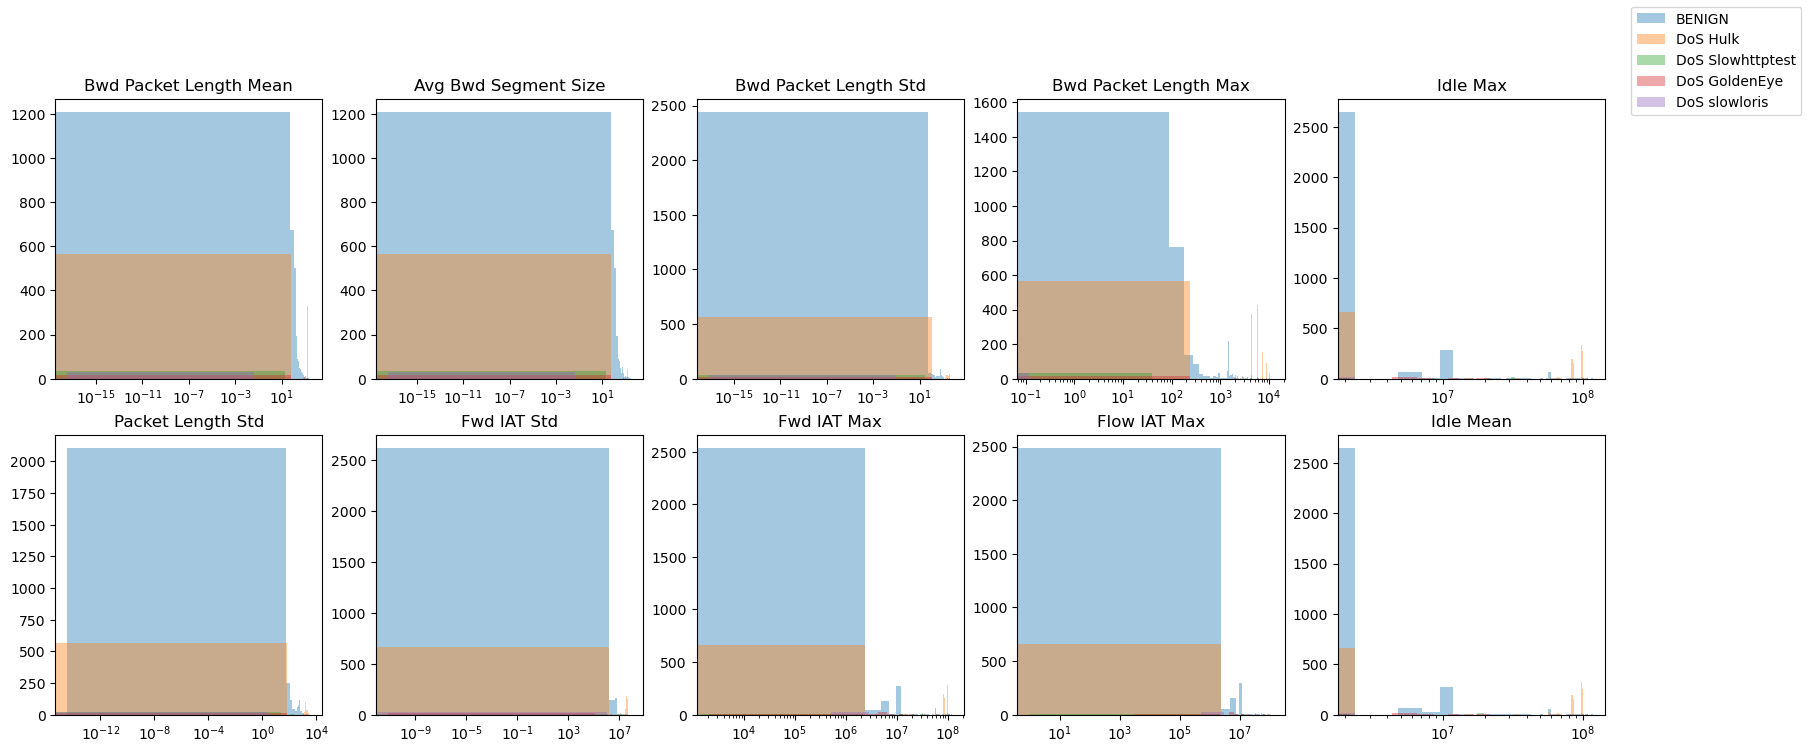

In [10]:
# Sample for speed
df_sample = df.sample(n=5000, random_state=42)

# Unique subclasses
classes = df_sample['Label'].unique()

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    ax = axes[i]
    
    for cls in classes:
        subset = df_sample[df_sample['Label'] == cls][feature]
        
        ax.hist(
            subset,
            bins=50,
            alpha=0.4,
            label=cls
        )
    
    ax.set_title(feature)
    ax.set_xscale('log')  # keep log scale (critical)

# Single legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

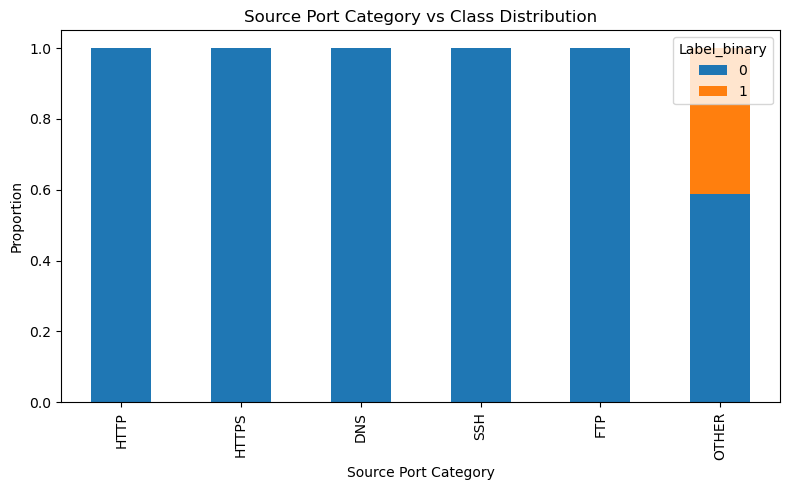

In [24]:
src_port_vs_class = pd.crosstab(
    df['SrcPortCategory'],
    df['Label_binary'],
    normalize='index'
)

order = ['HTTP', 'HTTPS', 'DNS', 'SSH', 'FTP', 'OTHER']
port_vs_class = port_vs_class.reindex(order)
src_port_vs_class = src_port_vs_class.reindex(order)
src_port_vs_class.plot(kind='bar', stacked=True, figsize=(8,5))
plt.title("Source Port Category vs Class Distribution")
plt.ylabel("Proportion")
plt.xlabel("Source Port Category")
plt.legend(title="Label_binary")
plt.tight_layout()
plt.show()



##### Q6 Further exploration charts based on ANOVA analysis: 
The histograms of the top ANOVA-selected features show clear differences between benign and attack traffic, particularly when viewed on a logarithmic scale. For features such as Fwd IAT Max, Flow IAT Max, Idle Max, and Idle Mean, benign traffic is tightly concentrated near lower values, while attack traffic exhibits a heavy right-skewed distribution with substantially higher variance (up to 10^7–10^8). This indicates that malicious flows are associated with longer and more irregular timing behavior. These distributional differences are consistent with the high ANOVA F-scores, confirming that these features exhibit strong between-class variance relative to within-class variance.

Similarly, packet-based features such as Bwd Packet Length Mean, Bwd Packet Length Max, and Packet Length Std show that benign traffic remains relatively compact, whereas attack traffic is more spread out and shifted toward higher values, reflecting greater variability in packet sizes.

However, across nearly all features, there is noticeable overlap between benign and attack traffic at lower value ranges. This is particularly evident near zero, where some attack samples follow patterns similar to normal traffic. The multiclass KDE plots further show that certain attack types, such as DoS slowloris and DoS GoldenEye, overlap significantly with benign traffic, making them harder to distinguish. This behavior is consistent with real-world scenarios, where attackers attempt to mimic normal traffic patterns to evade detection.

In addition to ANOVA-selected features, key network-level attributes such as flow duration, packet counts, and byte-based features exhibit similar patterns, with benign traffic concentrated at lower values and attack traffic showing heavier tails and greater variability.

Categorical port analysis further complements these findings. Destination port distributions show that HTTP traffic contains a higher proportion of attack samples, reflecting the presence of HTTP-based denial-of-service attacks in the dataset, while source ports provide weaker discriminatory power due to their dynamic assignment.

These combined observations indicate that effective classification will require integrating both continuous statistical features and categorical network features. Models capable of capturing nonlinear relationships, such as tree-based methods, are therefore better suited to handle the overlapping and skewed distributions observed in the data.

Although the ANOVA results identify these features as highly discriminative overall, the visualizations confirm that no single feature perfectly separates all classes. Separation is strongest in higher-value ranges, while ambiguity remains at lower values. This suggests that effective classification will require combining multiple features and using models capable of handling overlapping and non-linear decision boundaries.

These distributional properties suggest that tree-based models such as Random Forest and Gradient Boosting are better suited to this dataset, as they can capture nonlinear thresholds and handle skewed feature distributions effectively. In contrast, linear models such as Logistic Regression may struggle in regions where class overlap is high, particularly at lower feature values, leading to reduced recall for attack detection.

#### Q7: Attempt a few classifier  models and report  their 10-fold CV performances.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Original ANOVA-selected features
top_features = [
    'Bwd Packet Length Mean',
    'Avg Bwd Segment Size',
    'Bwd Packet Length Std',
    'Bwd Packet Length Max',
    'Idle Max',
    'Packet Length Std',
    'Fwd IAT Std',
    'Fwd IAT Max',
    'Flow IAT Max',
    'Idle Mean'
]

# Add domain-informed destination port features
port_features = [col for col in df.columns if col.startswith('dst_')]

# Combine
selected_features = top_features + port_features

# Remove duplicates (safe)
selected_features = list(dict.fromkeys(selected_features))

# Final X, y
X = df[selected_features]
y = df['Label_binary']

# Use stratified folds to preserve class balance across splits
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

scoring = ['accuracy', 'precision', 'recall', 'f1']
results = {}

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    
    results[name] = {}
    for metric in scoring:
        results[name][f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        results[name][f"{metric}_std"] = scores[f"test_{metric}"].std()

results_df = pd.DataFrame(results).T
results_df = results_df.round(4)
print(results_df)

/Users/drenard921/opt/anaconda3/envs/clean_env_2025/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


                     accuracy_mean  accuracy_std  precision_mean  \
Logistic Regression         0.9479        0.0007          0.8803   
Random Forest               0.9960        0.0003          0.9938   
Gradient Boosting           0.9919        0.0004          0.9870   

                     precision_std  recall_mean  recall_std  f1_mean  f1_std  
Logistic Regression         0.0015       0.9923      0.0005   0.9329  0.0009  
Random Forest               0.0003       0.9951      0.0007   0.9945  0.0004  
Gradient Boosting           0.0006       0.9910      0.0008   0.9890  0.0005  


##### Q7 Interpretation
The results show that tree-based ensemble methods significantly outperform Logistic Regression across all evaluation metrics. Random Forest achieved the highest overall performance (F1 = 0.9945), followed by Gradient Boosting (F1 = 0.9890), while Logistic Regression achieved a lower but still competitive performance (F1 = 0.9329).

Logistic Regression demonstrates very high recall (0.9923), indicating that it successfully identifies the majority of attack traffic. However, its lower precision (0.8803) suggests that it produces more false positives, classifying some benign traffic as malicious. This reflects the limitations of linear decision boundaries in capturing the complex and overlapping feature distributions observed in earlier analysis.

In contrast, Random Forest and Gradient Boosting achieve both high precision and high recall, indicating strong performance in correctly identifying both benign and malicious traffic. These models are better suited to this problem because they can capture nonlinear relationships and interactions between features such as packet timing, flow duration, and port-based patterns.

Because intrusion detection prioritizes minimizing false negatives, the high recall observed across all models is encouraging. However, Random Forest provides the best balance between precision and recall, making it the most effective model for this task.

The inclusion of destination port features further enhances model performance by capturing domain-specific patterns, particularly the strong association between HTTP traffic and attack behavior identified in earlier analysis.

One limitation of this evaluation is that ANOVA-based feature selection was performed prior to cross-validation, which may introduce mild information leakage and slightly optimistic performance estimates. Nevertheless, the relative performance differences between models remain informative.


#### Q8: Convert your code to be used for the remaining  7 datasets,  i.e., Datasets  2-8. 

In [26]:
def prepare_datasets(data_dir, top_features, exclude_keyword='Wednesday'):
    """
    Prepares datasets 2–8 using the same feature pipeline as Dataset 1.

    Returns:
        prepared_datasets (dict): {
            filename: {
                'X': feature matrix,
                'y': binary labels,
                'df': cleaned dataframe
            }
        }
    """

    dataset_files = [f for f in os.listdir(data_dir) if f.endswith('.csv')]
    dataset_files = [f for f in dataset_files if exclude_keyword not in f]

    prepared_datasets = {}

    # same port mapping used for Dataset 1
    important_ports = {
        80: "HTTP",
        443: "HTTPS",
        53: "DNS",
        22: "SSH",
        21: "FTP"
    }

    def categorize_port(port):
        try:
            port = int(port)
        except:
            return "OTHER"
        return important_ports.get(port, "OTHER")

    for file in dataset_files:
        file_path = os.path.join(data_dir, file)

        # Load safely
        try:
            df_temp = pd.read_csv(file_path, encoding='utf-8')
        except:
            df_temp = pd.read_csv(file_path, encoding='latin1')

        df_temp.columns = df_temp.columns.str.strip()

        if 'Label' not in df_temp.columns:
            print(f"{file}: skipped (no Label column)")
            continue

        # Binary labeling
        df_temp['Label_binary'] = (df_temp['Label'] != 'BENIGN').astype(int)

        # Port feature engineering
        if 'Source Port' in df_temp.columns and 'Destination Port' in df_temp.columns:
            df_temp['SrcPortCategory'] = df_temp['Source Port'].apply(categorize_port)
            df_temp['DstPortCategory'] = df_temp['Destination Port'].apply(categorize_port)

            src_dummies = pd.get_dummies(df_temp['SrcPortCategory'], prefix='src')
            dst_dummies = pd.get_dummies(df_temp['DstPortCategory'], prefix='dst')

            df_temp = pd.concat([df_temp, src_dummies, dst_dummies], axis=1)
        else:
            print(f"{file}: warning - missing port columns")

        # match Q7 feature logic
        port_features = [col for col in df_temp.columns if col.startswith('dst_')]
        selected_features = top_features + port_features
        selected_features = list(dict.fromkeys(selected_features))

        # make sure all expected columns exist
        for col in selected_features:
            if col not in df_temp.columns:
                df_temp[col] = 0

        X_temp = df_temp[selected_features].replace([np.inf, -np.inf], np.nan).fillna(0)
        y_temp = df_temp['Label_binary']

        prepared_datasets[file] = {
            'df': df_temp,
            'X': X_temp,
            'y': y_temp
        }

        print(f"{file}: X={X_temp.shape}, classes={y_temp.nunique()}")

    return prepared_datasets

In [27]:
prepared_datasets = prepare_datasets(
    data_dir='TrafficLabelling ',
    top_features=top_features
)

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: X=(288602, 16), classes=2
Monday-WorkingHours.pcap_ISCX.csv: X=(529918, 16), classes=1
Friday-WorkingHours-Morning.pcap_ISCX.csv: X=(191033, 16), classes=2
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: X=(286467, 16), classes=2
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: X=(225745, 16), classes=2
Tuesday-WorkingHours.pcap_ISCX.csv: X=(445909, 16), classes=2


/var/folders/_s/w6hdbcxj4_5dmvd3cyhy3p580000gn/T/ipykernel_3239/403269321.py:43: DtypeWarning: Columns (0,1,3,6,84) have mixed types. Specify dtype option on import or set low_memory=False.
  df_temp = pd.read_csv(file_path, encoding='latin1')


Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: X=(458968, 16), classes=2


#### Q9: Pick a classifier  algorithm  and report its evaluation  for the remaining  7 datasets. Note that one dataset  has a single  class, which might need  an unsupervised  learning.  
A Random Forest classifier was used as the primary model across all datasets due to its strong performance and robustness. For datasets containing multiple classes, the model was evaluated using 10-fold cross-validation. However, one dataset contained only a single class, making supervised classification infeasible. In this case, the pipeline would instead require an unsupervised or anomaly detection approach to identify deviations from normal behavior. This reflects real-world intrusion detection scenarios, where models must adapt to the availability of labeled data.

In [28]:
q9_results = {}

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

for file, data in prepared_datasets.items():
    X = data['X']
    y = data['y']
    
    print(f"\n=== {file} ===")
    
    # Handle single-class dataset
    if y.nunique() < 2:
        q9_results[file] = {
            'accuracy': None,
            'precision': None,
            'recall': None,
            'f1': None,
            'note': 'Single-class dataset; supervised classification not applicable'
        }
        print(q9_results[file]['note'])
        continue
    
    scores = cross_validate(
        rf_model,
        X,
        y,
        cv=10,
        scoring=['accuracy', 'precision', 'recall', 'f1'],
        n_jobs=-1
    )
    
    q9_results[file] = {
        'accuracy': scores['test_accuracy'].mean(),
        'precision': scores['test_precision'].mean(),
        'recall': scores['test_recall'].mean(),
        'f1': scores['test_f1'].mean(),
        'note': 'Random Forest evaluated successfully'
    }
    
    print(q9_results[file])

q9_results_df = pd.DataFrame(q9_results).T
metric_cols = ['accuracy', 'precision', 'recall', 'f1']
q9_results_df[metric_cols] = q9_results_df[metric_cols].astype(float).round(4)
q9_results_df


=== Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ===
{'accuracy': np.float64(0.9999376308980965), 'precision': np.float64(0.8333333333333333), 'recall': np.float64(0.575), 'f1': np.float64(0.64), 'note': 'Random Forest evaluated successfully'}

=== Monday-WorkingHours.pcap_ISCX.csv ===
Single-class dataset; supervised classification not applicable

=== Friday-WorkingHours-Morning.pcap_ISCX.csv ===
{'accuracy': np.float64(0.996115874439289), 'precision': np.float64(0.999), 'recall': np.float64(0.6228452294623433), 'f1': np.float64(0.7508681647956437), 'note': 'Random Forest evaluated successfully'}

=== Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv ===
{'accuracy': np.float64(0.9996544107845848), 'precision': np.float64(0.9996414207436721), 'recall': np.float64(0.9997357327125149), 'f1': np.float64(0.9996885327048586), 'note': 'Random Forest evaluated successfully'}

=== Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv ===
{'accuracy': np.float64(0.998888124706821

,accuracy,precision,recall,f1,note
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,0.9999,0.8333,0.5750,0.6400,Random Forest evaluated successfully
Monday-WorkingHours.pcap_ISCX.csv,NaN,NaN,NaN,NaN,Single-class dataset; supervised classification not applicable
Friday-WorkingHours-Morning.pcap_ISCX.csv,0.9961,0.9990,0.6228,0.7509,Random Forest evaluated successfully
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,0.9997,0.9996,0.9997,0.9997,Random Forest evaluated successfully
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,0.9989,0.9991,0.9990,0.9990,Random Forest evaluated successfully
Tuesday-WorkingHours.pcap_ISCX.csv,0.9996,0.9942,0.9941,0.9942,Random Forest evaluated successfully
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,0.9950,0.9996,0.9925,0.9959,Random Forest evaluated successfully


#### Q9 Interpretation of Results: 
The Random Forest classifier was applied to Datasets 2–8 using 10-fold cross-validation. Overall, the model achieved consistently high accuracy across most datasets, with values exceeding 0.99. However, as expected in imbalanced classification problems, accuracy alone does not fully capture performance, making precision, recall, and F1-score more informative metrics.

Performance varies significantly across datasets. For example, the PortScan and DDoS datasets achieved near-perfect performance (F1 ≈ 0.9997 and 0.9990), while Web Attacks and Tuesday also showed strong results (F1 ≈ 0.9959 and 0.9942). These results indicate that these attack types are highly separable from benign traffic, likely due to distinct traffic patterns such as high packet rates or characteristic port usage.

In contrast, the Infiltration dataset exhibits substantially lower recall (0.5750) and F1-score (0.6400), despite extremely high accuracy (0.9999). A similar pattern is observed in the Friday Morning dataset (recall ≈ 0.6228, F1 ≈ 0.7509). These results indicate that the model is failing to detect a significant portion of attack instances, instead classifying them as benign. This behavior is consistent with earlier exploratory analysis, where certain attack types showed strong overlap with benign traffic in feature distributions.

The variability in performance across datasets reflects differences in how well the selected features generalize. While ANOVA-selected temporal and packet-based features capture strong statistical patterns, and destination port features effectively identify attacks targeting specific services such as HTTP, these signals are less informative for more subtle attack types such as infiltration. These attacks do not produce extreme traffic patterns or rely on distinctive port behavior, making them more difficult to distinguish using the current feature set.

The Monday dataset contained only a single class and therefore could not be evaluated using supervised classification. In this case, no metrics were computed, and an unsupervised or anomaly detection approach would be more appropriate.

From a deployment perspective, these results highlight an important tradeoff. While Random Forest performs exceptionally well for clearly distinguishable attack types, its reduced recall in certain datasets underscores the challenge of detecting stealthy or low-signal attacks. In cybersecurity applications, false negatives are particularly costly, as missed attacks can lead to system compromise. Therefore, improving recall for datasets such as Infiltration should be prioritized, potentially through class rebalancing, threshold adjustment, or hybrid approaches that incorporate anomaly detection alongside supervised classification.



#### Q10: Briefly write up your thoughts  about  developing  a machine learning  model where you are not a subject matter expert, such as, developing  a cybersecurity intrusion  detection pipeline  as in this assignment. 


Developing a machine learning model in a domain where I am not a subject matter expert highlighted how transferable core data science principles are across fields. Concepts such as data preprocessing, feature selection, model evaluation, and cross-validation remained consistent, even when applied to a cybersecurity intrusion detection problem. This reinforced the idea that a strong foundation in data science allows one to approach unfamiliar domains with a structured and effective workflow.

At the same time, working with this dataset emphasized the importance of domain knowledge for deeper interpretation. While it was possible to build models and achieve strong performance metrics, understanding why certain features (such as ports, packet sizes, or timing behavior) were important required learning aspects of network behavior and attack patterns. This made the process more engaging, as it involved not only applying technical skills but also gaining insight into how real-world systems operate.

Overall, this experience demonstrated that machine learning development is both domain-agnostic and domain-enhanced: the methodology can be applied broadly, but domain expertise improves feature interpretation, model trust, and the ability to draw meaningful conclusions.

#### References
Agrawal, R., Imieliński, T., & Swami, A. (1993). Mining association rules between sets of items in large databases. ACM SIGMOD Record, 22(2), 207–216. https://doi.org/10.1145/170036.170072 

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.